# Credit Default Risk Analysis
### Exploratory Data Analysis & Preprocessing
This notebook walks through the data preparation, data cleaning, and feature exploration for predicting credit default based on borrower financial behavior.

### 1. Environment Setup & Data Loading
Importing standard data analysis libraries and loading the dataset.

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [120]:
data= pd.read_csv("GiveMeSomeCredit (1).csv")

print("shape", data.shape)
data.head(10)

shape (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
5,1,1.459344,54,F,3,3,1718.000000,NaN,18,9,0,7,0.0,2
6,1,14.540918,45,F,3,3,1.151865,3726.0,11,0,2,7,3.0,3
7,1,0.915053,48,M,2,1,0.652057,2600.0,8,0,1,7,0.0,3
8,1,1.000000,31,F,2,0,503.000000,NaN,4,7,0,7,0.0,2
9,0,1.445042,38,F,3,0,0.136132,4715.0,5,3,0,7,2.0,0


Checking column types, memory footprint, and overall schema.

In [121]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  object 
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  

### 2. Data Cleaning & Preprocessing
Creating a working copy and encoding categorical features into numeric format.

In [122]:
df = data.copy()

Encoding `SEX` as binary (0 = Male, 1 = Female).

In [123]:
df["SEX"] = df["SEX"].map({
    "M": 0,
    "F": 1
})

In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  int64  
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  

Inspecting missing values across all attributes.

In [125]:
data.isna().sum()

SeriousDlqin                                0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
SEX                                         0
EDUCATION                                   0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29607
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3893
NumberOfDefault                             0
dtype: int64

### 3. Target Variable Analysis
Examining class balance for the default target (`SeriousDlqin`).

In [126]:
target = "SeriousDlqin"

print("Target:", target)
print("Unique values:")
print(df[target].unique())

Target: SeriousDlqin
Unique values:
[1 0]


In [127]:
target_summary = pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": df[target].value_counts(normalize=True).mul(100).round(2)
})

target_summary

,Count,Percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


### 4. Handling Duplicates & Data Integrity
Identifying and removing duplicate rows.

In [128]:
df[df.duplicated(keep=False)]

,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
30045,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30050,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30067,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30070,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
121347,0,1.0,22,1,1,0,0.0,929.0,1,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149706,0,0.0,42,0,3,0,0.0,NaN,2,0,0,0,0.0,0
149709,0,0.0,79,1,3,0,0.0,NaN,1,0,0,0,NaN,0
149714,0,0.0,23,1,2,0,0.0,NaN,2,0,0,0,0.0,0
149717,0,0.0,59,1,1,0,0.0,NaN,1,0,0,0,0.0,0


In [129]:
df = df.drop_duplicates().reset_index(drop=True)

### 5. Correlation & Feature Screening
Calculating linear correlation against the target to identify strong relationships and potential data leakage.

In [130]:
corr = df.corr()

corr[target].sort_values(ascending=False)

SeriousDlqin                            1.000000
NumberOfDefault                         0.921531
NumberOfTimes90DaysLate                 0.314540
NumberOfTime30-59DaysPastDueNotWorse    0.274490
NumberOfTime60-89DaysPastDueNotWorse    0.268093
NumberOfDependents                      0.047301
EDUCATION                               0.002202
RevolvingUtilizationOfUnsecuredLines   -0.001631
SEX                                    -0.002661
NumberRealEstateLoansOrLines           -0.004126
DebtRatio                              -0.008839
MonthlyIncome                          -0.023377
NumberOfOpenCreditLinesAndLoans        -0.024591
age                                    -0.113190
Name: SeriousDlqin, dtype: float64

`NumberOfDefault` appears to be a direct post-event outcome (data leakage), so we drop it before training/modeling.

In [131]:
df = df.drop(columns=["NumberOfDefault"])

### 6. Outlier Filtering & Missing Value Imputation
Filtering out unrealistic ages (e.g., ages under 18 or over 100).

In [132]:
print((df['age'] < 18).sum())
print((df["age"] > 100).sum())

1
13


In [133]:
df = df[(df["age"] >= 18) & (df["age"] <= 100)]

Imputing missing values: median for skewed `MonthlyIncome` and mean for `NumberOfDependents`.

In [134]:
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())
df["NumberOfDependents"] = df["NumberOfDependents"].fillna(df["NumberOfDependents"].mean())

### 7. Feature Subset Selection for Focused EDA
Extracting key drivers: credit utilization, 90+ days delinquency, and borrower age.

In [135]:
features = ["RevolvingUtilizationOfUnsecuredLines", "NumberOfTimes90DaysLate", "age"]

In [136]:
df_test = df[[target] + features].copy()

In [144]:
df_test = df_test.rename(columns={"SeriousDlqin": target})

In [145]:
df_test

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate,age
0,1,0.878881,2,40
1,0,1.000000,0,34
2,0,0.470085,6,59
3,1,0.908082,1,26
4,1,1.000000,1,36
...,...,...,...,...
149577,0,0.000000,0,32
149578,0,0.000000,0,59
149579,0,0.000000,0,66
149580,0,0.000000,0,76


### 8. Exploratory Data Analysis (EDA)
Defining a helper function for summary stats, distributions, and default rates across classes.

In [146]:
import seaborn as sns

sns.set_theme(style="whitegrid")
target = "SeriousDlqin2yrs"
labels = {0: "No default", 1: "Default"}

def summary(col, data=df_test):
    s = data[col]
    print(f"--- {col} ---")
    print("Missing %:", round(s.isna().mean() * 100, 2))
    print("Zeros %  :", round((s == 0).mean() * 100, 2))
    print("Skewness :", round(s.skew(), 2))
    print(s.describe(percentiles=[.01, .25, .5, .75, .99]).round(2))
    print("\nBy class:")
    print(data.groupby(target)[col].agg(["mean", "median", "std"]).round(3))

#### Feature 1: Age
Analyzing age distributions across default vs. non-default borrowers and default rate by age cohort.

C:\Users\Victus\AppData\Local\Temp\ipykernel_5224\1887138758.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(["No default (0)", "Default (1)"])


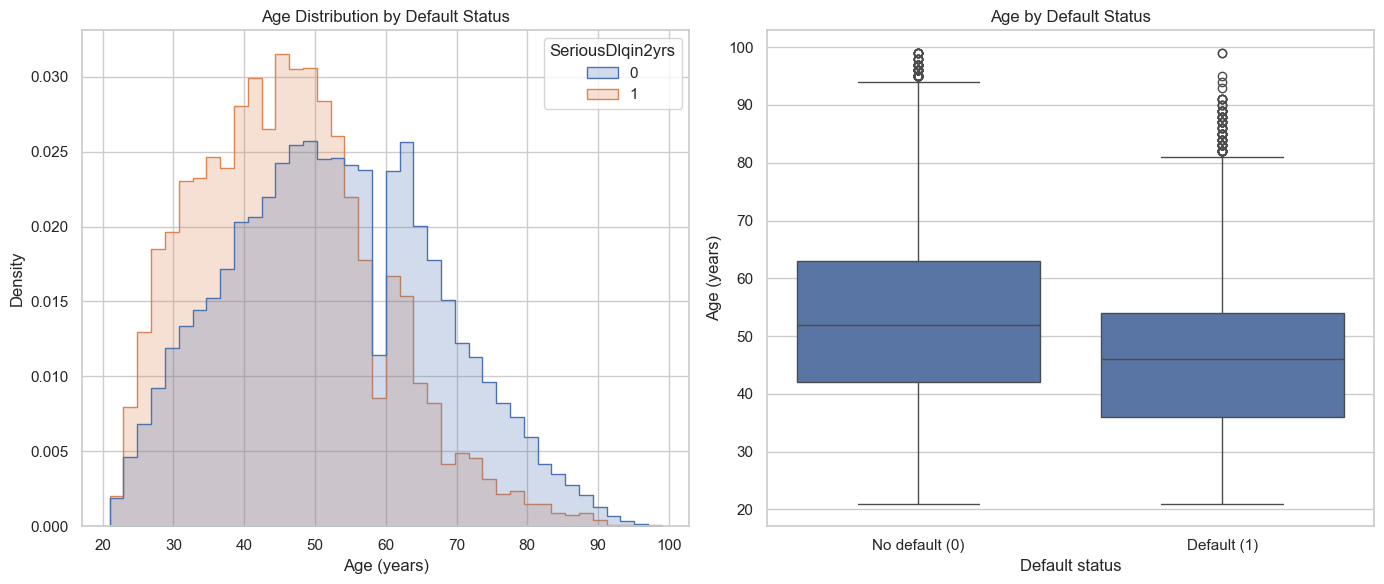

age
(18, 30]     11.15
(30, 40]      9.74
(40, 50]      8.20
(50, 60]      6.11
(60, 120]     2.98
Name: SeriousDlqin2yrs, dtype: float64


In [ ]:
# summary("age")

d = df_test.copy()  # حذف سن‌های غیرمنطقی
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(data=d, x="age", hue=target, bins=40, stat="density",
             common_norm=False, element="step", ax=ax[0])
ax[0].set_title("Age Distribution by Default Status")
ax[0].set_xlabel("Age (years)"); ax[0].set_ylabel("Density")

sns.boxplot(data=d, x=target, y="age", ax=ax[1])
ax[1].set_xticklabels(["No default (0)", "Default (1)"])
ax[1].set_title("Age by Default Status")
ax[1].set_xlabel("Default status"); ax[1].set_ylabel("Age (years)")
plt.tight_layout()
plt.show()

bins = pd.cut(d["age"], [18, 30, 40, 50, 60, 120])
print((d.groupby(bins, observed=True)[target].mean() * 100).round(2))

#### Feature 2: Revolving Utilization of Unsecured Lines
Investigating credit utilization ratio. Capping visual outliers at the 99th percentile and evaluating default rate across utilization tiers.

--- RevolvingUtilizationOfUnsecuredLines ---
Missing %: 0.0
Zeros %  : 7.22
Skewness : 67.67
count    149568.00
mean          5.72
std         213.00
min           0.00
1%            0.00
25%           0.03
50%           0.15
75%           0.56
99%           1.09
max       29110.00
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

By class:
                   mean  median      std
SeriousDlqin2yrs                        
0                 5.817   0.133  217.557
1                 4.418   0.830  132.819
Values > 1: 3320


C:\Users\Victus\AppData\Local\Temp\ipykernel_5224\2316872480.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(["No default (0)", "Default (1)"])


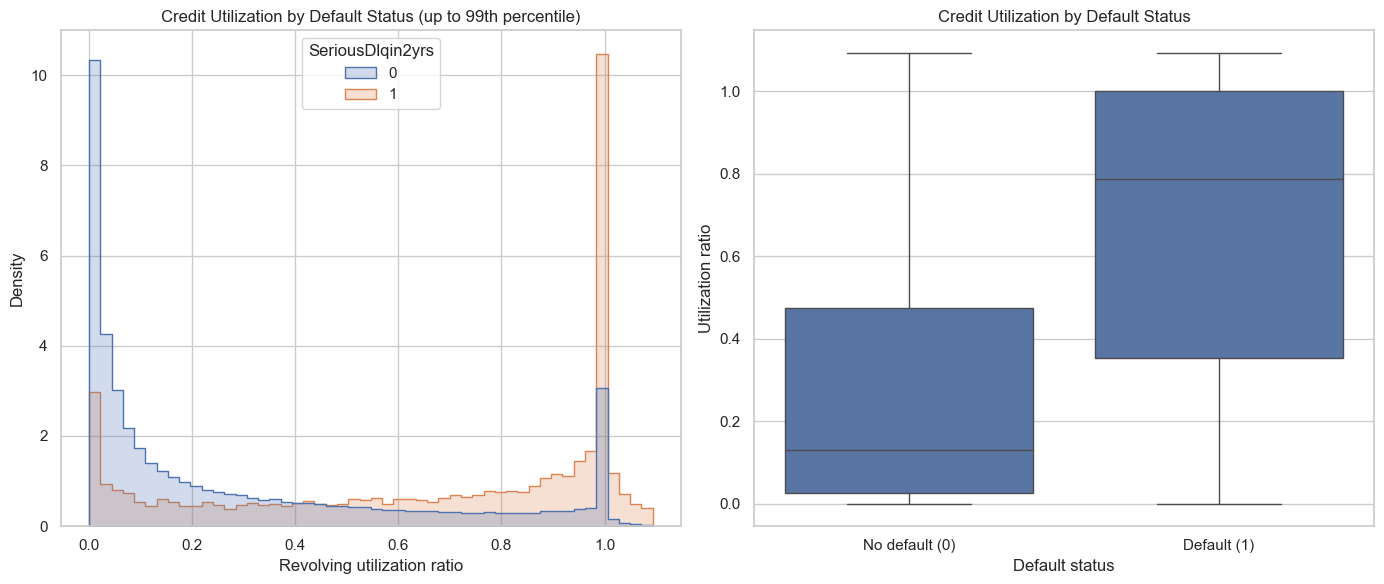

RevolvingUtilizationOfUnsecuredLines
0-25%       2.14
25-50%      5.29
50-75%     10.13
75-100%    17.86
>100%      37.26
Name: SeriousDlqin2yrs, dtype: float64


In [155]:
col = "RevolvingUtilizationOfUnsecuredLines"
summary(col)
print("Values > 1:", (df_test[col] > 1).sum())

cap = df_test[col].quantile(0.99)
d = df_test[df_test[col] <= cap]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.histplot(data=d, x=col, hue=target, bins=50, stat="density",
             common_norm=False, element="step", ax=ax[0])
ax[0].set_title("Credit Utilization by Default Status (up to 99th percentile)")
ax[0].set_xlabel("Revolving utilization ratio"); ax[0].set_ylabel("Density")

sns.boxplot(data=d, x=target, y=col, ax=ax[1])
ax[1].set_xticklabels(["No default (0)", "Default (1)"])
ax[1].set_title("Credit Utilization by Default Status")
ax[1].set_xlabel("Default status"); ax[1].set_ylabel("Utilization ratio")
plt.tight_layout(); plt.show()

# نرخ نکول در بازه‌های مصرف
bins = pd.cut(df_test[col], [-0.01, 0.25, 0.5, 0.75, 1, np.inf],
              labels=["0-25%", "25-50%", "50-75%", "75-100%", ">100%"])
print((df_test.groupby(bins, observed=True)[target].mean() * 100).round(2))

#### Feature 3: Number of Times 90+ Days Late
Cleaning anomalous records (96/98 placeholder codes), binning delinquency counts, and comparing default rates.

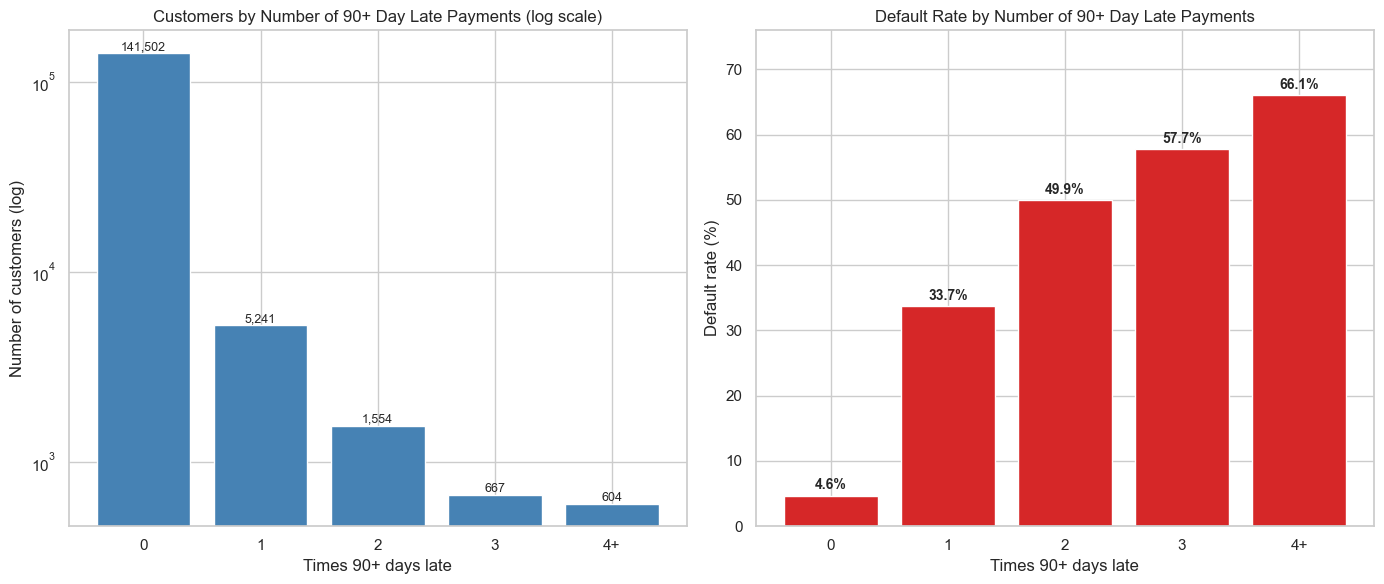

             rate       n
late_group               
0            4.63  141502
1           33.68    5241
2           49.94    1554
3           57.72     667
4+          66.06     604


In [162]:
col = "NumberOfTimes90DaysLate"
data = df_test[df_test[col] < 90].copy()   # حذف کدهای 96/98

# گروه‌بندی: 0, 1, 2, 3, 4+
data["late_group"] = data[col].clip(upper=4).astype(int).astype(str)
data.loc[data[col] >= 4, "late_group"] = "4+"
order = ["0", "1", "2", "3", "4+"]

stats = (data.groupby("late_group")[target]
             .agg(rate="mean", n="size")
             .reindex(order))
stats["rate"] *= 100
overall = data[target].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# --- چپ: تعداد مشتریان (لگاریتمی) ---
bars = ax[0].bar(stats.index, stats["n"], color="steelblue")
ax[0].set_yscale("log")
ax[0].set_title("Customers by Number of 90+ Day Late Payments (log scale)")
ax[0].set_xlabel("Times 90+ days late"); ax[0].set_ylabel("Number of customers (log)")
for b, n in zip(bars, stats["n"]):
    ax[0].text(b.get_x() + b.get_width()/2, n, f"{n:,}", ha="center", va="bottom", fontsize=9)

# --- راست: نرخ نکول ---
bars = ax[1].bar(stats.index, stats["rate"], color="tab:red")

ax[1].set_title("Default Rate by Number of 90+ Day Late Payments")
ax[1].set_xlabel("Times 90+ days late"); ax[1].set_ylabel("Default rate (%)")
for b, r in zip(bars, stats["rate"]):
    ax[1].text(b.get_x() + b.get_width()/2, r + 1, f"{r:.1f}%", ha="center", fontsize=10, fontweight="bold")
ax[1].set_ylim(0, stats["rate"].max() * 1.15)

plt.tight_layout()
plt.show()
print(stats.round(2))